In [1]:
import pandas as pd
from rdkit import Chem

INPUT_CSV = "samplingDHA1.csv"     # ajusta nombre/ruta
SMILES_COL = "SMILES"             # ajusta si tu CSV usa otra columna

SCAFFOLD = "CC1CCC2C(C)C(O[*:1])OC3OC4(C)CCC1C32OO4" 

In [2]:
df = pd.read_csv(INPUT_CSV)
df.head(), df.columns

(                                              SMILES  SMILES_state  \
 0  COc1cc([N+](=O)[O-])c(OC)cc1COC1OC2OC3(C)CCC4C...             1   
 1  Cc1cn(COCc2cccc3c2C=C3c2ccc([N+](=O)[O-])cc2)c...             1   
 2  CC1CCC2C(C)C(OC(=O)Cc3ccc(F)c(Cl)c3)OC3OC4(C)C...             1   
 3  CC1CCC2C(C)C(Oc3ccn(-c4c(F)c(F)c(F)c(F)c4F)c(=...             1   
 4  COc1cc(N)nc(NCCOC2OC3OC4(C)CCC5C(C)CCC(C2C)C35...             1   
 
                                 Scaffold  \
 0  CC1CCC2C(C)C(O[*])OC3OC4(C)CCC1C32OO4   
 1  CC1CCC2C(C)C(O[*])OC3OC4(C)CCC1C32OO4   
 2  CC1CCC2C(C)C(O[*])OC3OC4(C)CCC1C32OO4   
 3  CC1CCC2C(C)C(O[*])OC3OC4(C)CCC1C32OO4   
 4  CC1CCC2C(C)C(O[*])OC3OC4(C)CCC1C32OO4   
 
                                             R-groups    NLL  
 0                   *Cc1c(OC)cc([N+]([O-])=O)c(OC)c1  13.74  
 1  C(CCC(=O)*)c1c(C)c2c(c3c1OCO3)C(=O)N(COCc1c3c(...  53.68  
 2                           c1c(F)c(Cl)cc(CC(*)=O)c1  14.93  
 3  n1(-c2c(F)c(F)c(F)c(F)c2F)c(=S)c(-c2ccc(OCc3

In [3]:
scaf = Chem.MolFromSmiles(SCAFFOLD)
assert scaf is not None, "No pude parsear el scaffold. Revisa el SMILES."

# Encuentra el átomo [*:1] y su vecino O
star = None
for a in scaf.GetAtoms():
    if a.GetAtomicNum() == 0 and a.GetAtomMapNum() == 1:
        star = a
        break

assert star is not None, "El scaffold no contiene [*:1]."

nbrs = list(star.GetNeighbors())
assert len(nbrs) == 1, "Esperaba que [*:1] tuviera exactamente 1 vecino en el scaffold."
o_in_scaffold = nbrs[0]
assert o_in_scaffold.GetSymbol() == "O", f"El vecino de [*:1] no es O, es {o_in_scaffold.GetSymbol()}."

# Convertimos el scaffold a SMARTS para hacer substructure matching en productos
scaf_query = Chem.MolFromSmarts(Chem.MolToSmarts(scaf))
o_query_idx = o_in_scaffold.GetIdx()

o_query_idx

8

In [4]:
from rdkit.Chem.rdchem import BondType

def is_carbonyl_carbon(atom_c):
    """True si C tiene un doble enlace a O (C=O)."""
    if atom_c.GetSymbol() != "C":
        return False
    for b in atom_c.GetBonds():
        if b.GetBondType() == BondType.DOUBLE:
            other = b.GetOtherAtom(atom_c)
            if other.GetSymbol() == "O":
                return True
    return False

def classify_dha_substitution(smiles):
    """
    Devuelve:
      - "invalid" si RDKit no parsea
      - "ether" si el O del scaffold está unido a C no carbonílico
      - "non_ether" en caso contrario (incluye éster/carbonato, O-N, O-S, etc.)
      - "no_scaffold" si no matchea scaffold (raro en LibInvent, pero posible)
    """
    m = Chem.MolFromSmiles(smiles)
    if m is None:
        return "invalid"

    matches = m.GetSubstructMatches(scaf_query)
    if not matches:
        return "no_scaffold"

    for match in matches:
        match_set = set(match)
        o_idx_in_mol = match[o_query_idx]
        o_atom = m.GetAtomWithIdx(o_idx_in_mol)

        # vecinos del O en la molécula final
        neigh = list(o_atom.GetNeighbors())
        if len(neigh) < 2:
            continue

        # el vecino fuera del scaffold-match es el sustituyente R
        outside = [a for a in neigh if a.GetIdx() not in match_set]
        if len(outside) != 1:
            continue

        r_atom = outside[0]

        # debe ser O–C
        if r_atom.GetSymbol() != "C":
            continue

        # excluir O–C(=O)
        if is_carbonyl_carbon(r_atom):
            continue

        return "ether"

    return "non_ether"

In [5]:
# Clasifica cada SMILES
classes = df[SMILES_COL].astype(str).map(classify_dha_substitution)
df["class"] = classes

df["class"].value_counts()

class
no_scaffold    323
Name: count, dtype: int64

In [6]:
ethers = df[df["class"] == "ether"].copy()
non_ethers = df[df["class"].isin(["non_ether", "no_scaffold"])].copy()
invalid = df[df["class"] == "invalid"].copy()

ethers.to_csv("samplingDHA1_ethers.csv", index=False)
non_ethers.to_csv("samplingDHA1_non_ethers.csv", index=False)
invalid.to_csv("samplingDHA1_invalid.csv", index=False)

print("Total:", len(df))
print("Ethers:", len(ethers))
print("Non-ethers/no_scaffold:", len(non_ethers))
print("Invalid:", len(invalid))

Total: 323
Ethers: 0
Non-ethers/no_scaffold: 323
Invalid: 0


In [7]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem.rdchem import BondType

# ---- Config ----
INPUT_CSV = "samplingDHA1.csv"      # <-- cambia ruta/nombre si aplica
SMILES_COL = "SMILES"              # <-- cambia si tu columna se llama distinto
SCAFFOLD = "CC1CCC2C(C)C(O[*:1])OC3OC4(C)CCC1C32OO4"

OUT_ETHERS = "samplingDHA1_ethers.csv"
OUT_NON_ETHERS = "samplingDHA1_non_ethers.csv"
OUT_INVALID = "samplingDHA1_invalid.csv"

# ---- Load ----
df = pd.read_csv(INPUT_CSV)
if SMILES_COL not in df.columns:
    raise ValueError(f"No encuentro columna '{SMILES_COL}'. Columnas disponibles: {list(df.columns)}")

# ---- Prepare scaffold query and locate O attached to [*:1] ----
scaf = Chem.MolFromSmiles(SCAFFOLD)
if scaf is None:
    raise ValueError("No pude parsear el scaffold. Revisa el SMILES del scaffold.")

star = None
for a in scaf.GetAtoms():
    if a.GetAtomicNum() == 0 and a.GetAtomMapNum() == 1:
        star = a
        break
if star is None:
    raise ValueError("El scaffold no contiene [*:1].")

nbrs = list(star.GetNeighbors())
if len(nbrs) != 1:
    raise ValueError("Esperaba que [*:1] tuviera exactamente 1 vecino en el scaffold.")
o_in_scaffold = nbrs[0]
if o_in_scaffold.GetSymbol() != "O":
    raise ValueError(f"El vecino de [*:1] no es O sino {o_in_scaffold.GetSymbol()}.")

scaf_query = Chem.MolFromSmarts(Chem.MolToSmarts(scaf))
o_query_idx = o_in_scaffold.GetIdx()

def is_carbonyl_carbon(atom_c):
    """True si el carbono tiene un doble enlace a oxígeno (C=O)."""
    if atom_c.GetSymbol() != "C":
        return False
    for b in atom_c.GetBonds():
        if b.GetBondType() == BondType.DOUBLE and b.GetOtherAtom(atom_c).GetSymbol() == "O":
            return True
    return False

def classify_dha_ether(smiles: str) -> str:
    """
    Clasifica específicamente el enlace del O del scaffold (O[*:1]):

    - 'ether'      : O del scaffold unido a carbono NO carbonílico (incluye O-alkyl y O-aryl)
    - 'non_ether'  : O unido a C(=O) (éster/carbonato/carbamato) o a N/S/etc o caso raro
    - 'no_scaffold': no contiene el scaffold
    - 'invalid'    : RDKit no parsea el SMILES
    """
    m = Chem.MolFromSmiles(smiles)
    if m is None:
        return "invalid"

    matches = m.GetSubstructMatches(scaf_query)
    if not matches:
        return "no_scaffold"

    for match in matches:
        match_set = set(match)
        o_idx_in_mol = match[o_query_idx]
        o_atom = m.GetAtomWithIdx(o_idx_in_mol)

        outside = [a for a in o_atom.GetNeighbors() if a.GetIdx() not in match_set]
        if len(outside) != 1:
            continue

        r_atom = outside[0]

        if r_atom.GetSymbol() != "C":      # éter debe ser O–C
            continue
        if is_carbonyl_carbon(r_atom):     # excluye O–C(=O)
            continue

        return "ether"

    return "non_ether"

# ---- Apply filter ----
df["class"] = df[SMILES_COL].astype(str).str.strip().map(classify_dha_ether)

# ---- Split + save ----
ethers = df[df["class"] == "ether"].copy()
non_ethers = df[df["class"].isin(["non_ether", "no_scaffold"])].copy()
invalid = df[df["class"] == "invalid"].copy()

ethers.to_csv(OUT_ETHERS, index=False)
non_ethers.to_csv(OUT_NON_ETHERS, index=False)
invalid.to_csv(OUT_INVALID, index=False)

# ---- Summary + quick sanity preview ----
print("Columns:", list(df.columns))
print(df["class"].value_counts())
print("\nSaved:")
print(" -", OUT_ETHERS, "rows:", len(ethers))
print(" -", OUT_NON_ETHERS, "rows:", len(non_ethers))
print(" -", OUT_INVALID, "rows:", len(invalid))

print("\nExample ethers:")
print(ethers[SMILES_COL].head(5).to_list())
print("\nExample non-ethers:")
print(non_ethers[SMILES_COL].head(5).to_list())

Columns: ['SMILES', 'SMILES_state', 'Scaffold', 'R-groups', 'NLL', 'class']
class
no_scaffold    323
Name: count, dtype: int64

Saved:
 - samplingDHA1_ethers.csv rows: 0
 - samplingDHA1_non_ethers.csv rows: 323
 - samplingDHA1_invalid.csv rows: 0

Example ethers:
[]

Example non-ethers:
['COc1cc([N+](=O)[O-])c(OC)cc1COC1OC2OC3(C)CCC4C(C)CCC(C1C)C24OO3', 'Cc1cn(COCc2cccc3c2C=C3c2ccc([N+](=O)[O-])cc2)c(=O)c2c3c(c(CCCC(=O)OC4OC5OC6(C)CCC7C(C)CCC(C4C)C57OO6)c(C)c12)OCO3', 'CC1CCC2C(C)C(OC(=O)Cc3ccc(F)c(Cl)c3)OC3OC4(C)CCC1C32OO4', 'CC1CCC2C(C)C(Oc3ccn(-c4c(F)c(F)c(F)c(F)c4F)c(=S)c3-c3ccc(OCc4ccccc4)cc3)OC3OC4(C)CCC1C32OO4', 'COc1cc(N)nc(NCCOC2OC3OC4(C)CCC5C(C)CCC(C2C)C35OO4)n1']


In [8]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem.rdchem import BondType

INPUT_CSV = "samplingDHA1.csv"

# 1) Scaffold CORE sin attachment point (sin *)
CORE = "CC1CCC2C(C)C(O)OC3OC4(C)CCC1C32OO4"

OUT_ETHERS = "samplingDHA1_ethers.csv"
OUT_NON_ETHERS = "samplingDHA1_non_ethers.csv"
OUT_INVALID = "samplingDHA1_invalid.csv"

df = pd.read_csv(INPUT_CSV)

# --- Detecta columna de SMILES del PRODUCTO ---
candidate_cols = [c for c in df.columns if c.lower() in ["smiles", "sampled_smiles", "mol", "structure"]]
if not candidate_cols:
    # fallback: usa la primera columna que parezca SMILES (string) y que NO sea scaffold/r-group
    candidate_cols = [c for c in df.columns if df[c].dtype == object]

def looks_like_product_smiles(s):
    if not isinstance(s, str): 
        return False
    s = s.strip()
    if len(s) < 5:
        return False
    # productos finales normalmente NO tienen '*'
    if "*" in s:
        return False
    # heurística simple: contiene C/N/O y dígitos/anillos a veces
    return any(ch in s for ch in ["C","N","O","c","n","o"])

smiles_col = None
best_score = -1
for c in candidate_cols:
    sample = df[c].dropna().astype(str).head(50).tolist()
    score = sum(looks_like_product_smiles(x) for x in sample)
    if score > best_score:
        best_score = score
        smiles_col = c

if smiles_col is None or best_score <= 0:
    raise ValueError(f"No pude detectar una columna de SMILES de producto. Columnas: {list(df.columns)}")

print("Usando columna de producto:", smiles_col, " (score:", best_score, ")")

core = Chem.MolFromSmiles(CORE)
if core is None:
    raise ValueError("No pude parsear el CORE. Revisa el SMILES del core.")

core_query = Chem.MolFromSmarts(Chem.MolToSmarts(core))

def is_carbonyl_carbon(atom_c):
    if atom_c.GetSymbol() != "C":
        return False
    for b in atom_c.GetBonds():
        if b.GetBondType() == BondType.DOUBLE and b.GetOtherAtom(atom_c).GetSymbol() == "O":
            return True
    return False

def classify_ether_on_core(smiles):
    """
    Busca el core en la molécula final.
    Encuentra el oxígeno del core que tenga un vecino fuera del core (el O sustituido).
    Ether si ese vecino externo es C y no es carbonílico.
    """
    m = Chem.MolFromSmiles(smiles)
    if m is None:
        return "invalid"

    matches = m.GetSubstructMatches(core_query)
    if not matches:
        return "no_core"

    for match in matches:
        match_set = set(match)
        # busca O en el match que tenga vecino fuera del match (el sustituyente)
        for idx in match:
            a = m.GetAtomWithIdx(idx)
            if a.GetSymbol() != "O":
                continue
            outside = [n for n in a.GetNeighbors() if n.GetIdx() not in match_set]
            if len(outside) != 1:
                continue
            r_atom = outside[0]
            # Debe ser O–C
            if r_atom.GetSymbol() != "C":
                continue
            # No debe ser carbonilo: excluye O–C(=O)
            if is_carbonyl_carbon(r_atom):
                continue
            return "ether"

    return "non_ether"

df["class"] = df[smiles_col].astype(str).str.strip().map(classify_ether_on_core)

print(df["class"].value_counts())

ethers = df[df["class"] == "ether"].copy()
non_ethers = df[df["class"].isin(["non_ether", "no_core"])].copy()
invalid = df[df["class"] == "invalid"].copy()

ethers.to_csv(OUT_ETHERS, index=False)
non_ethers.to_csv(OUT_NON_ETHERS, index=False)
invalid.to_csv(OUT_INVALID, index=False)

print("\nSaved:")
print(" -", OUT_ETHERS, "rows:", len(ethers))
print(" -", OUT_NON_ETHERS, "rows:", len(non_ethers))
print(" -", OUT_INVALID, "rows:", len(invalid))

print("\nExample ethers:")
print(ethers[smiles_col].head(5).to_list())
print("\nExample non-ethers:")
print(non_ethers[smiles_col].head(5).to_list())

Usando columna de producto: SMILES  (score: 50 )
class
ether        221
non_ether    102
Name: count, dtype: int64

Saved:
 - samplingDHA1_ethers.csv rows: 221
 - samplingDHA1_non_ethers.csv rows: 102
 - samplingDHA1_invalid.csv rows: 0

Example ethers:
['COc1cc([N+](=O)[O-])c(OC)cc1COC1OC2OC3(C)CCC4C(C)CCC(C1C)C24OO3', 'CC1CCC2C(C)C(Oc3ccn(-c4c(F)c(F)c(F)c(F)c4F)c(=S)c3-c3ccc(OCc4ccccc4)cc3)OC3OC4(C)CCC1C32OO4', 'COc1cc(N)nc(NCCOC2OC3OC4(C)CCC5C(C)CCC(C2C)C35OO4)n1', 'CC1CCC2C(C)C(OCc3cc(F)c(F)c(F)c3F)OC3OC4(C)CCC1C32OO4', 'CC1CCC2C(C)C(OCCn3cnc4ncnc(NCc5c(F)cc(F)c(F)c5F)c43)OC3OC4(C)CCC1C32OO4']

Example non-ethers:
['Cc1cn(COCc2cccc3c2C=C3c2ccc([N+](=O)[O-])cc2)c(=O)c2c3c(c(CCCC(=O)OC4OC5OC6(C)CCC7C(C)CCC(C4C)C57OO6)c(C)c12)OCO3', 'CC1CCC2C(C)C(OC(=O)Cc3ccc(F)c(Cl)c3)OC3OC4(C)CCC1C32OO4', 'CC(=O)OCCc1cc(OCCNC(=O)OC2OC3OC4(C)CCC5C(C)CCC(C2C)C35OO4)cc2oc(=O)c(-c3ccc(O)cc3)c(-c3ccc(F)cc3)c12', 'CC1CCC2C(C)C(OC(=O)c3ccc(N=N)cc3Oc3ccc(F)cc3F)OC3OC4(C)CCC1C32OO4', 'CC1CCC2C(C)C(OC(=O)CCCN

In [9]:
from rdkit import Chem

# Cargar el archivo de ethers
ethers = pd.read_csv("samplingDHA1_ethers.csv")

# SMARTS: oxígeno unido a un carbono carbonílico (O-C(=O))
ocoo = Chem.MolFromSmarts("O[C](=O)")

def has_ester_like(m):
    return m is not None and m.HasSubstructMatch(ocoo)

ms = [Chem.MolFromSmiles(s) for s in ethers["SMILES"].astype(str)]
bad = [i for i,m in enumerate(ms) if has_ester_like(m)]

print("Ethers total:", len(ethers))
print("Con motivo O-C(=O) en alguna parte:", len(bad))
print("Ejemplos (si hay):", ethers.iloc[bad[:5]]["SMILES"].to_list())

Ethers total: 221
Con motivo O-C(=O) en alguna parte: 25
Ejemplos (si hay): ['CC1CCC2C(C)C(OCC3CN(c4ccccc4)C(=O)O3)OC3OC4(C)CCC1C32OO4', 'CC1CCC2C(C)C(OCc3cc(C(=O)Nc4ccc(CC(=O)O)cc4)cc(Oc4ccc(F)c(F)c4)c3O)OC3OC4(C)CCC1C32OO4', 'CC1CCC2C(C)C(OCC(=O)OCCCNc3nccc(-c4cnc5ccccc5n4)n3)OC3OC4(C)CCC1C32OO4', 'CC1CCC2C(C)C(OCCOC(=O)c3cc(OCc4ccccc4F)c(OCc4ccccc4)c4ccc5ccccc5c34)OC3OC4(C)CCC1C32OO4', 'CC1CCC2C(C)C(OCc3cccc(C(=O)OC(C#N)CCCCc4ccccc4)c3)OC3OC4(C)CCC1C32OO4']


In [10]:
from rdkit.Chem.rdchem import BondType

CORE = "CC1CCC2C(C)C(O)OC3OC4(C)CCC1C32OO4"
core = Chem.MolFromSmiles(CORE)
core_query = Chem.MolFromSmarts(Chem.MolToSmarts(core))

def is_carbonyl_carbon(atom_c):
    if atom_c.GetSymbol() != "C":
        return False
    for b in atom_c.GetBonds():
        if b.GetBondType() == BondType.DOUBLE and b.GetOtherAtom(atom_c).GetSymbol() == "O":
            return True
    return False

def core_link_is_ether(smiles):
    m = Chem.MolFromSmiles(smiles)
    if m is None:
        return False

    matches = m.GetSubstructMatches(core_query)
    if not matches:
        return False

    for match in matches:
        match_set = set(match)
        for idx in match:
            a = m.GetAtomWithIdx(idx)
            if a.GetSymbol() != "O":
                continue
            outside = [n for n in a.GetNeighbors() if n.GetIdx() not in match_set]
            if len(outside) != 1:
                continue
            r_atom = outside[0]
            if r_atom.GetSymbol() != "C":
                continue
            if is_carbonyl_carbon(r_atom):
                continue
            return True
    return False

# Chequea todos
fails = []
for i, smi in enumerate(ethers["SMILES"].astype(str)):
    if not core_link_is_ether(smi):
        fails.append(i)

print("Ethers total:", len(ethers))
print("Que NO pasan la verificación exacta:", len(fails))
print("Ejemplos fallidos:", ethers.iloc[fails[:5]]["SMILES"].to_list())

Ethers total: 221
Que NO pasan la verificación exacta: 0
Ejemplos fallidos: []


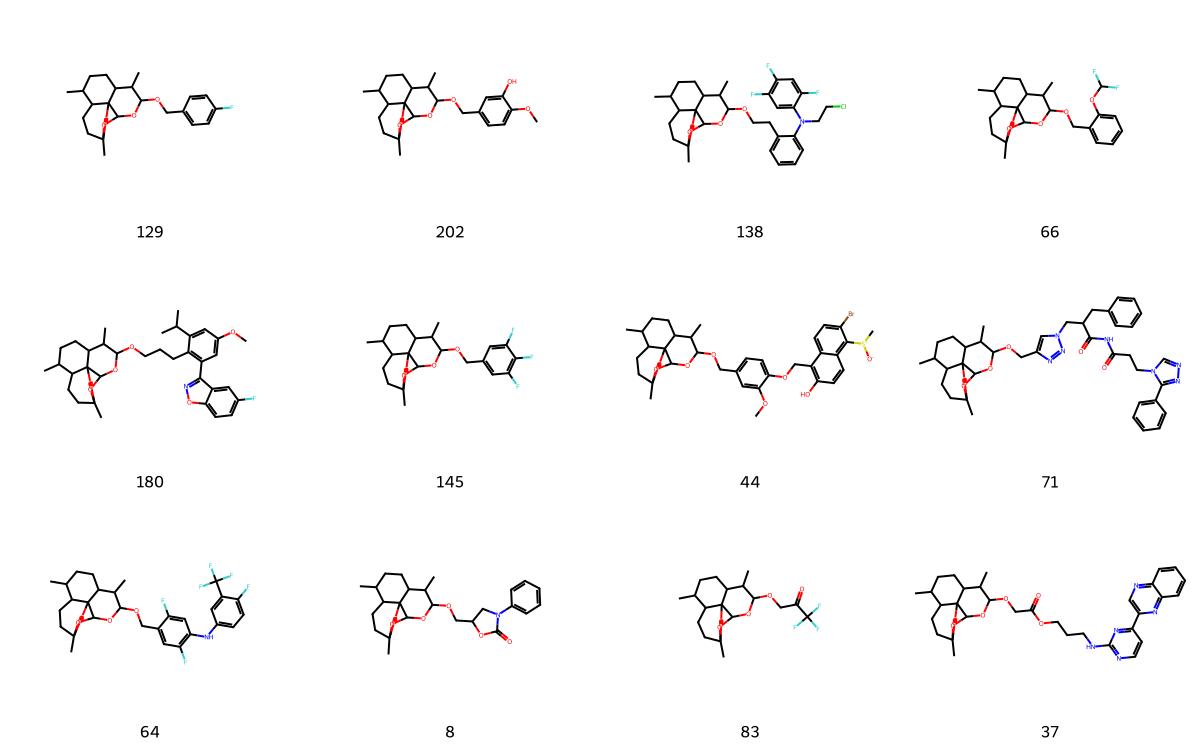

In [11]:
import random
from rdkit.Chem import Draw

sample = ethers.sample(n=min(12, len(ethers)), random_state=0)
mols = [Chem.MolFromSmiles(s) for s in sample["SMILES"].astype(str)]
Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(300, 250), legends=[str(i) for i in sample.index])